In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [40]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [41]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [257]:
def grad_old(activations, weights, biases, inputs, outputs):
    
    grad_activation = [0*act for act in activations]
    grad_bias = [0*bias for bias in biases]
    grad_weight = [0*weight for weight in weights]
    
    for k in range(len(biases[-2])):
        grad_activation[-2][k] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * weights[-1][j][k] for j in range(len(outputs))])

    for i in range(len(biases[-3])):
        grad_activation[-3][i] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * weights[-2][k][i] for k in range(len(biases[-2]))]) for j in range(len(outputs))])

    for m in range(len(biases[-4])):
        grad_activation[-4][m] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * sum([weights[-2][k][i] * sigma_der(np.dot(weights[-3][i], activations[-4]) + 
                                    biases[-3][i]) * weights[-3][i][m] for i in range(len(biases[-3]))]) for k in range(len(biases[-2]))]) 
                                      for j in range(len(outputs))])
        
    
    for j in range(len(outputs)):
        grad_bias[-1][j] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                biases[-1][j])

    for k in range(len(biases[-2])):
        grad_bias[-2][k] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k])
    
    for k in range(len(biases[-3])):
        grad_bias[-3][k] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k])

    for k in range(len(biases[-4])):
        grad_bias[-4][k] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k])

    
    
    
    for j in range(len(outputs)):
        for k in range(len(biases[-2])):
            grad_weight[-1][j][k] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * activations[-2][k]

    for k in range(len(biases[-2])):
        for i in range(len(biases[-3])):
            grad_weight[-2][k][i] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k]) * activations[-3][i]

    for k in range(len(biases[-3])):
        for i in range(len(biases[-4])):
            grad_weight[-3][k][i] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k]) * activations[-4][i]

    for k in range(len(biases[-4])):
        for i in range(len(inputs)):
            grad_weight[-4][k][i] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k]) * inputs[i]
            
    
    return grad_activation, grad_weight, grad_bias

In [ ]:
#def nested_sum(act, wt, bs, k, i, L):

    #if L == i+1:
        #return 1

   #else:
       # return sum([wt[L-1][k][m] * sigma_der(np.dot(wt[L-1][m], act[L-2]) + bs[L-1]) for m in range(len(act[L-2))])
       # * nested_sum(act, wt, bs, k, i, L-1)
    

In [214]:
#x = np.array([2, 7, 8])
#factor = np.where((x > 5) & (x % 2 == 0), 1, 2) 
#result = x * factor
#print(result)

In [ ]:
   #for i in range(L-1): 
        #for j in range(len(act[i])):
            #gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * 
                                #np.where((L > 2) & (L-i-1 > 1), sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]), 1) * 
                                #np.where((L > 3) & (L-i-1 > 2), sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]), 1) *
                                #np.where((L > 4) & (L-i-1 > 3), sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]), 1) * 
                                #np.where((L > 5) & (L-i-1 > 4), sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]), 1) *
                                #np.where((L > 6) & (L-i-1 > 5), sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]), 1) * 
                                #np.where((L > 7) & (L-i-1 > 6), sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]), 1) *
                                #np.where((L > 8) & (L-i-1 > 7), sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]), 1) * 
                                #np.where((L > 9) & (L-i-1 > 8), sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]), 1) *
                                #np.where((L > 10) & (L-i-1 > 9), sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                                #for t in ind[1]]), 1) for s in ind[2]]) for r in ind[3]]) for q in ind[4]]) for p in ind[5]]) 
                                #for o in ind[6]]) for n in ind[7]]) for m in ind[8]]) for l in ind[9]]) for k in ind[10]])

    #for i in range(L-1): 
        #for j in range(len(act[i])):
            #gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * np.where(i == L-2, wt[-1][k][j], 
             #np.where(L-i-1 > 1, sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * np.where(i == L-3, wt[-2][l][j], 1) * 
             #np.where(L-i-1 > 2, sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * np.where(i == L-4, wt[-3][m][j], 1) *
             #np.where(L-i-1 > 3, sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * np.where(i == L-5, wt[-4][n][j], 1) *
             #np.where(L-i-1 > 4, sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * np.where(i == L-6, wt[-5][o][j], 1) *
             #np.where(L-i-1 > 5, sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * np.where(i == L-7, wt[-6][p][j], 1) *
             #np.where(L-i-1 > 6, sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * np.where(i == L-8, wt[-7][q][j], 1) *
             #np.where(L-i-1 > 7, sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * np.where(i == L-9, wt[-8][r][j], 1) *
             #np.where(L-i-1 > 8, sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * np.where(i == L-10, wt[-9][s][j], 1) *
             #np.where(L-i-1 > 9, sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    #for t in ind[-10]]), 1) for s in ind[-9]]) for r in ind[-8]]) for q in ind[-7]]) for p in ind[-6]]) 
                    #for o in ind[-5]]) for n in ind[-4]]) for m in ind[-3]]) for l in ind[-2]]))) for k in ind[-1]])

In [49]:
#def grad(act, wt, bs, ins, outs):
    
    #gr_act = [0*a for a in act]
    #gr_bs = [0*b for b in bs]
    #gr_wt = [0*w for w in wt]

    #L = len(act)

    #ind = []   
    #for i in range(L):
        #ind.append(list(range(len(act[i]))))


    #for i in range(L-1): 
        #for j in range(len(act[i])):
            #gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * np.where(i == L-2, wt[-1][k][j], 
                #sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * np.where(i == L-3, wt[-2][l][j],  
                #sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * np.where(i == L-4, wt[-3][m][j], 
                #sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * np.where(i == L-5, wt[-4][n][j], 
                #sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * np.where(i == L-6, wt[-5][o][j],
                #sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * np.where(i == L-7, wt[-6][p][j],
                #sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * np.where(i == L-8, wt[-7][q][j],
                #sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * np.where(i == L-9, wt[-8][r][j],
                #sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * np.where(i == L-10, wt[-9][s][j], 
                #sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    #for t in ind[-10]])) for s in ind[-9]])) for r in ind[-8]])) for q in ind[-7]])) for p in ind[-6]])) 
                    #for o in ind[-5]])) for n in ind[-4]])) for m in ind[-3]])) for l in ind[-2]])) for k in ind[-1]])
      
    #return gr_act, gr_wt, gr_bs

In [258]:
def grad_new(act, wt, bs, ins, outs):
    
    gr_act = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    ind = []   
    for i in range(L):
        ind.append(list(range(len(act[i]))))


    for i in range(L-1): 
        for j in range(len(act[i])):
            gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * (wt[-1][k][j] if i == L-2 
                else sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * (wt[-2][l][j] if i == L-3 
                else sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * (wt[-3][m][j] if i == L-4 
                else sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * (wt[-4][n][j] if i == L-5 
                else sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * (wt[-5][o][j] if i == L-6
                else sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * (wt[-6][p][j] if i == L-7
                else sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * (wt[-7][q][j] if i == L-8
                else sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * (wt[-8][r][j] if i == L-9
                else sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * (wt[-9][s][j] if i == L-10 
                else sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    for t in ind[-10]])) for s in ind[-9]])) for r in ind[-8]])) for q in ind[-7]])) for p in ind[-6]])) 
                    for o in ind[-5]])) for n in ind[-4]])) for m in ind[-3]])) for l in ind[-2]])) for k in ind[-1]])
            
    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                gr_bs[i][j] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])
        elif i == 0:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j])
        else:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])

    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]
        elif i == 0:
            for j in range(len(bs[i])):
                for k in range(len(ins)):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j]) * ins[k]
        else:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]         

    
    return gr_act, gr_wt, gr_bs

In [33]:
#def nested_sum(indices, depth=0): #Recursive function for computing nested sums.
    #if depth == len(indices):  # Base case: No more nesting
        #return sum(indices)  # Replace with your calculation
    
    #total = 0
    #for _ in range(indices[depth]):  # Loop over the current depth range
        #total += nested_sum(indices, depth + 1)  # Recursive call to deeper level
    #return total

#indices = [4, 2, 3]  # Two levels of summation: sum(i=0..2) sum(j=0..1) f(i, j)
#result = nested_sum(indices)
#print(result)

In [34]:
#from itertools import product

#indices = [3, 2, 3]  # Two nested sums: sum(i=0..2) sum(j=0..1)
#result = sum(sum(idx) for idx in product(*(range(n) for n in indices)))

#result

In [35]:
#math.prod(x for x in ind[0] if x != 0)

In [36]:
#nested_list = [[1, 2, 3, 4], [1, 2], [1, 2, 3, 4], [1, 2, 3, 4, 5]]

#math.prod(sum(sublist) for sublist in nested_list)

In [37]:
#10*3*10*15

In [38]:
#import itertools

# Generate all possible combinations by taking one element from each sublist
#combinations = itertools.product(*nested_list)

# Compute the sum of the products
#result = sum(math.prod(comb) for comb in combinations)

#print(result)

In [264]:
def neural_network_compare(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations):

    biases = []
    for i in range(len(nodes_hidden_layers)):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs[0])))

    biases_old = biases
    biases_new = biases
    
    weights = []
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs[0]))))
    
    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs[0]), nodes_hidden_layers[-1])))

    weights_old = weights
    weights_new = weights
    
    cost_old = []
    cost_new = []

    
    for k in range(iterations):

        iter_cost_old = 0
        iter_cost_new = 0

        gr_b_old = [0*bias for bias in biases]
        gr_w_old = [0*weight for weight in weights]
        gr_act_old = gr_b_old

        gr_b_new = gr_b_old
        gr_w_new = gr_w_old
        gr_act_new = gr_act_old
        
        for j in range(inputs.shape[0]):        
            
            activations_old = det_activations(inputs[j], weights_old, biases_old)
            iter_cost_old +=  (1/inputs.shape[0]) * sum([(activations_old[-1].tolist()[i] - outputs[j][i])**2 for i in range(len(outputs[j]))])

            activations_new = det_activations(inputs[j], weights_new, biases_new)
            iter_cost_new +=  (1/inputs.shape[0]) * sum([(activations_new[-1].tolist()[i] - outputs[j][i])**2 for i in range(len(outputs[j]))])
        
            gr_act_p_old, gr_w_p_old, gr_b_p_old = grad_old(activations_old, weights_old, biases_old, inputs[j], outputs[j])
            gr_act_p_new, gr_w_p_new, gr_b_p_new = grad_new(activations_new, weights_new, biases_new, inputs[j], outputs[j])

            gr_b_old = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_b_old, gr_b_p_old)]
            gr_w_old = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_w_old, gr_w_p_old)]
            gr_act_old = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_act_old, gr_act_p_old)]

            gr_b_new = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_b_new, gr_b_p_new)]
            gr_w_new = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_w_new, gr_w_p_new)]
            gr_act_new = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_act_new, gr_act_p_new)]
            
        weights_old = [w - learning_rate * gw for w, gw in zip(weights_old, gr_w_old)]
        biases_old = [b - learning_rate * gb for b, gb in zip(biases_old, gr_b_old)]

        weights_new = [w - learning_rate * gw for w, gw in zip(weights_new, gr_w_new)]
        biases_new = [b - learning_rate * gb for b, gb in zip(biases_new, gr_b_new)]

        cost_old.append(iter_cost_old)
        cost_new.append(iter_cost_new)

    return activations_old, weights_old, biases_old, cost_old, activations_new, weights_new, biases_new, cost_new

In [265]:
inputs = np.random.rand(4,20)
outputs = [[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]]

In [266]:
activations_old, weights_old, biases_old, cost_old, activations_new, weights_new, biases_new, cost_new = neural_network_compare(inputs, outputs, [5, 5, 5], 1, 1, 1, 100) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

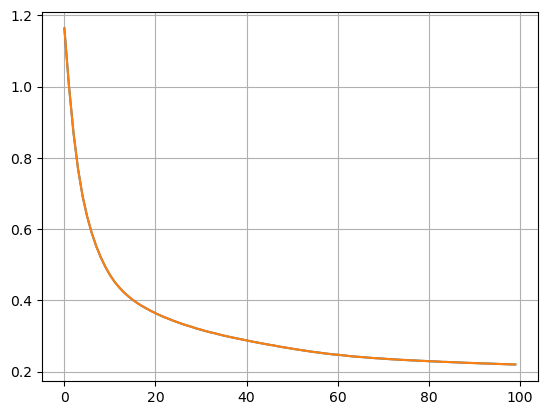

In [267]:
plt.plot(cost_old);
plt.plot(cost_new);
plt.grid();

In [268]:
activations_old[-1]

array([0.43 , 0.123, 0.278, 0.361, 0.092, 0.652])

In [269]:
activations_new[-1]

array([0.43 , 0.123, 0.278, 0.361, 0.092, 0.652])